# Assessment-Lab-4 - 18.9.26
## Machine Learning Lab - BCSE209P
### Kanad Bhattacharya, 23BCE1265

#### Question

    1. Generate the model to classify the data using PCA (4 components) for
       dimensionality reduction and logistic regression for the given dataset
       “raisin.csv”. Use 70:30 split and analyze the performance of the data
       and visualize the results.

    2. Generate the model to cluster the air quality data using Self Organizing
       Map (SOM) method for the given dataset “aqi.csv”. Use the features -
       'pm25', 'pm10', 'co', 'o3'. Analyze the performance of the data and
       visualize the results.

### 1.

### PCA + Logistic Regression - Raisin classification

#### Load dataset

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from minisom import MiniSom

In [40]:
raisin_df = pd.read_csv('Assessment Lab 4- 18.9.26/Raisin.csv')
raisin_df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


#### Features & target

In [41]:
X_raisin = raisin_df.drop(columns='Class')
y_raisin = raisin_df['Class']

#### Train-test split

In [42]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_raisin, y_raisin, test_size=0.3, random_state=1265, stratify=y_raisin
)

#### Feature scaling

In [43]:
scaler = StandardScaler()
X_train_r_scaled = scaler.fit_transform(X_train_r)
X_test_r_scaled = scaler.transform(X_test_r)

#### PCA (4 components)

In [44]:
pca = PCA(n_components=4, random_state=1265)
X_train_r_pca = pca.fit_transform(X_train_r_scaled)
X_test_r_pca = pca.transform(X_test_r_scaled)

print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance retained: {pca.explained_variance_ratio_.sum():.4f}")

Explained variance ratio: [0.68914551 0.21157481 0.08713749 0.00783119]
Total variance retained: 0.9957


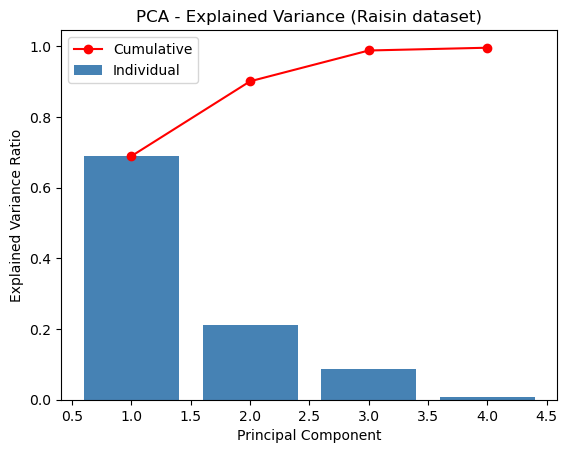

In [45]:
plt.bar(range(1, 5), pca.explained_variance_ratio_, color='steelblue', label='Individual')
plt.plot(range(1, 5), np.cumsum(pca.explained_variance_ratio_), color='red', marker='o', label='Cumulative')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA - Explained Variance (Raisin dataset)')
plt.legend()
plt.show()

#### Train model

In [46]:
log_reg_pca = LogisticRegression(max_iter=1000, random_state=1265)
log_reg_pca.fit(X_train_r_pca, y_train_r)

y_pred_r = log_reg_pca.predict(X_test_r_pca)

#### Performance evaluation

In [47]:
pca_accuracy = accuracy_score(y_test_r, y_pred_r)
print(f"Accuracy: {pca_accuracy:.4f}")
print()
print("Classification Report:")
print(classification_report(y_test_r, y_pred_r))

Accuracy: 0.8593

Classification Report:
              precision    recall  f1-score   support

       Besni       0.85      0.87      0.86       135
     Kecimen       0.87      0.84      0.86       135

    accuracy                           0.86       270
   macro avg       0.86      0.86      0.86       270
weighted avg       0.86      0.86      0.86       270



#### Visualize results

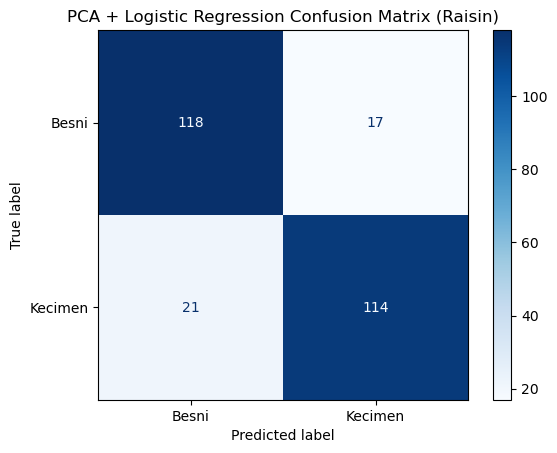

In [48]:
cm_r = confusion_matrix(y_test_r, y_pred_r, labels=log_reg_pca.classes_)
disp_r = ConfusionMatrixDisplay(confusion_matrix=cm_r, display_labels=log_reg_pca.classes_)
disp_r.plot(cmap='Blues')
plt.title('PCA + Logistic Regression Confusion Matrix (Raisin)')
plt.show()

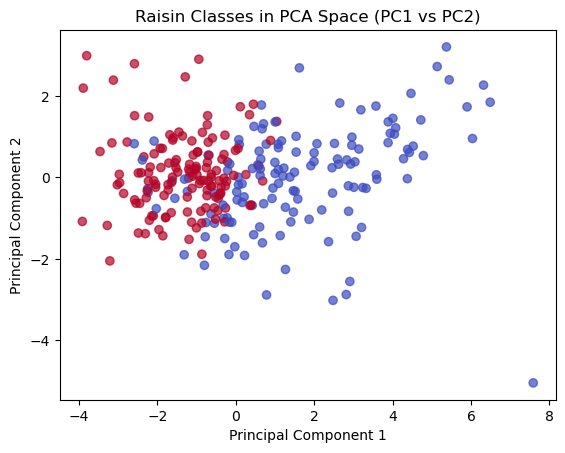

In [49]:
plt.scatter(X_test_r_pca[:, 0], X_test_r_pca[:, 1], c=(y_test_r == 'Kecimen'), cmap='coolwarm', alpha=0.7)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Raisin Classes in PCA Space (PC1 vs PC2)')
plt.show()

### 2.

### Self Organizing Map - Air quality clustering

#### Load dataset

In [50]:
aqi_df = pd.read_csv('Assessment Lab 4- 18.9.26/aqi.csv')
aqi_df.head()

,city,pm25,pm10,no2,so2,co,o3
0,Delhi,99.868566,147.103280,49.715328,19.615149,0.729754,46.487946
1,Delhi,143.168513,208.517207,32.957884,14.712800,0.660975,43.014054
2,Delhi,89.678491,101.412886,14.126233,9.188562,0.496151,54.713710
3,Delhi,43.679037,65.432963,61.984732,10.871118,0.820258,28.628777
4,Delhi,58.224691,110.443143,22.735096,13.878490,0.619808,45.624594


#### Select features

In [51]:
features_aqi = ['pm25', 'pm10', 'co', 'o3']

X_aqi = aqi_df[features_aqi].values

#### Feature scaling

In [52]:
scaler_aqi = StandardScaler()
X_aqi_scaled = scaler_aqi.fit_transform(X_aqi)

#### Train SOM

In [53]:
som_grid = 10

som = MiniSom(x=som_grid, y=som_grid, input_len=len(features_aqi),
              sigma=1.0, learning_rate=0.5, random_seed=1265)
som.random_weights_init(X_aqi_scaled)
som.train_random(X_aqi_scaled, 20000, verbose=False)

print(f"Quantization Error: {som.quantization_error(X_aqi_scaled):.4f}")

Quantization Error: 0.5966


#### Performance evaluation

In [54]:
# Assign each sample to its winning (best matching) neuron
winners = np.array([som.winner(x) for x in X_aqi_scaled])
winner_ids = winners[:, 0] * som_grid + winners[:, 1]

active_neurons = len(set(map(tuple, winners)))
print(f"Active neurons used: {active_neurons} / {som_grid * som_grid}")
print(f"Quantization Error: {som.quantization_error(X_aqi_scaled):.4f}")

Active neurons used: 100 / 100
Quantization Error: 0.5966


#### Visualize results

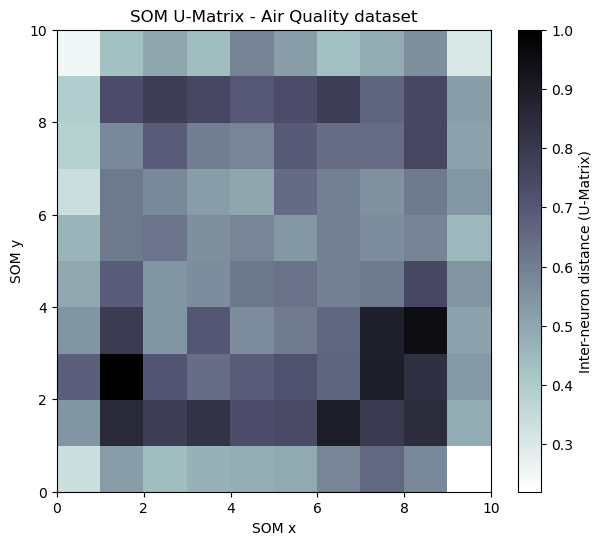

In [55]:
plt.figure(figsize=(7, 6))
plt.pcolor(som.distance_map().T, cmap='bone_r')
plt.colorbar(label='Inter-neuron distance (U-Matrix)')
plt.title('SOM U-Matrix - Air Quality dataset')
plt.xlabel('SOM x')
plt.ylabel('SOM y')
plt.show()

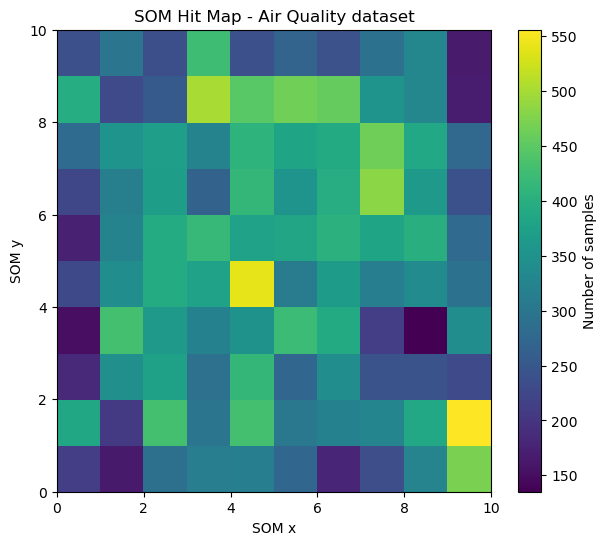

In [56]:
hit_counts = np.zeros((som_grid, som_grid))
for w in winners:
    hit_counts[w[0], w[1]] += 1

plt.figure(figsize=(7, 6))
plt.pcolor(hit_counts.T, cmap='viridis')
plt.colorbar(label='Number of samples')
plt.title('SOM Hit Map - Air Quality dataset')
plt.xlabel('SOM x')
plt.ylabel('SOM y')
plt.show()

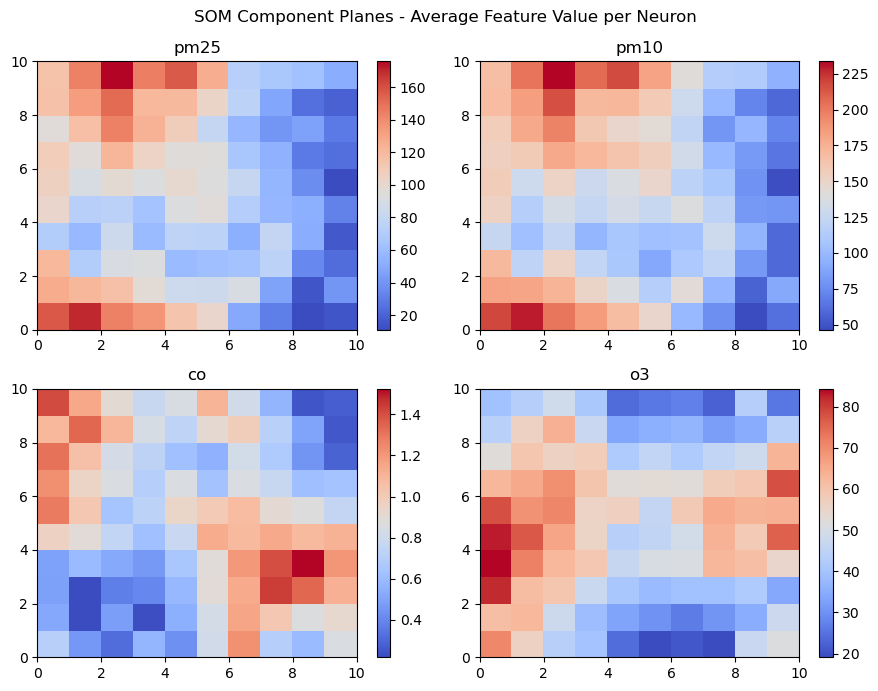

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))

for ax, feature in zip(axes.ravel(), features_aqi):
    feature_map = np.zeros((som_grid, som_grid))
    counts = np.zeros((som_grid, som_grid))
    for x, w in zip(X_aqi[:], winners):
        feature_map[w[0], w[1]] += x[features_aqi.index(feature)]
        counts[w[0], w[1]] += 1
    counts[counts == 0] = 1
    feature_map /= counts

    im = ax.pcolor(feature_map.T, cmap='coolwarm')
    ax.set_title(feature)
    fig.colorbar(im, ax=ax)

plt.suptitle('SOM Component Planes - Average Feature Value per Neuron')
plt.tight_layout()
plt.show()